# Accessible and dangerous space proxies

**Analytical question:** Integrate reachability and weight dangerous space.

**Stages in this notebook:** Control surface; grid-cell area; danger weight; per-cell contributions; totals.

This is one complete analytical workflow. Its helper functions and intermediate steps are sections within the notebook, rather than separate notebooks. All required code is inline: downloading, kloppy loading, reshaping, plotting and method calculations. No local `.py` helper or prior notebook session is required. Set `DATA_ROOT` below to reuse another cache; absent data are downloaded from the pinned SkillCorner open-data revision.

Run top to bottom and inspect each intermediate table and visual before interpreting the final result. Some calculations are explicitly teaching baselines or synthetic training checks, not exact research/provider implementations or measured soccer-model performance. Dependencies are listed in the repository requirements and the imports below.


**Reading order:** follow the numbered stages. Each helper is introduced before its first use, then its intermediate output is inspected. The final result comes after those stages.

## 1. Imports and data location

In [1]:
from pathlib import Path
import json, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from IPython.display import display
from kloppy import skillcorner

# Change DATA_ROOT to use an existing cache elsewhere. No local Python modules are imported.
candidates=[Path.cwd(),*Path.cwd().parents]
ROOT=next((p for p in candidates if (p/'data/1925299/1925299_match.json').exists()),Path.cwd())
DATA_ROOT=ROOT/'data/1925299'


## 2. Inline ingestion and plotting helpers

In [2]:
def ensure_sample(destination):
    """Download only missing data files. Tracking is bounded to 9000 source records."""
    destination.mkdir(parents=True,exist_ok=True)
    revision='4340d274572876239c154c90bc507a9b3250a656'
    base=f'https://raw.githubusercontent.com/SkillCorner/opendata/{revision}/data/matches/1925299/'
    for suffix in ['match.json','dynamic_events.csv','phases_of_play.csv']:
        name='1925299_'+suffix;target=destination/name
        if not target.exists():
            with urllib.request.urlopen(base+name,timeout=90) as response:target.write_bytes(response.read())
    name='1925299_tracking_extrapolated.jsonl';target=destination/name
    if not target.exists():
        url=base.replace('raw.githubusercontent.com/','media.githubusercontent.com/media/')+name
        temporary=destination/(name+'.partial')
        with urllib.request.urlopen(url,timeout=90) as response,temporary.open('wb') as output:
            count=0
            for line in response:
                if line.strip():
                    json.loads(line);output.write(line);count+=1
                if count>=9000:break
        temporary.replace(target)

def read_tracking(destination):
    """Load kloppy coordinates and explicitly reshape player columns to rows."""
    dataset=skillcorner.load(meta_data=destination/'1925299_match.json',raw_data=destination/'1925299_tracking_extrapolated.jsonl',coordinates='skillcorner')
    wide=dataset.to_df()
    metadata=json.loads((destination/'1925299_match.json').read_text(encoding='utf-8'))
    raw=[json.loads(line) for line in (destination/'1925299_tracking_extrapolated.jsonl').read_text().splitlines() if line.strip()]
    player_possession={r['frame']:str(r.get('possession',{}).get('player_id')) for r in raw}
    visibility={(r['frame'],str(p['player_id'])):p.get('is_detected') for r in raw for p in r.get('player_data',[])}
    parts=[]
    for p in metadata['players']:
        pid=str(p['id'])
        if f'{pid}_x' not in wide:continue
        part=wide[['period_id','frame_id','timestamp','ball_owning_team_id',f'{pid}_x',f'{pid}_y']].copy()
        part.columns=['period_id','frame_id','timestamp','team_in_possession','x','y']
        part['player_id']=pid;part['team_id']=p['team_id'];part['name']=p['short_name'];parts.append(part)
    tracking=pd.concat(parts,ignore_index=True)
    tracking['seconds']=tracking.timestamp.dt.total_seconds()
    tracking['player_in_possession']=tracking.frame_id.map(player_possession)
    tracking['is_detected']=[visibility.get((f,p)) for f,p in zip(tracking.frame_id,tracking.player_id)]
    tracking=tracking.sort_values(['player_id','period_id','frame_id'])
    return dataset,wide,tracking,metadata,raw

def pitch(ax=None):
    """Draw a 105 by 68 metre pitch in native centered coordinates."""
    if ax is None:_,ax=plt.subplots(figsize=(9,5.5))
    ax.set_facecolor('#eef3ed')
    ax.add_patch(Rectangle((-52.5,-34),105,68,fill=False,color='#597063'))
    ax.plot([0,0],[-34,34],c='#597063');ax.add_patch(Circle((0,0),9.15,fill=False,color='#597063'))
    for x in [-52.5,36]:ax.add_patch(Rectangle((x,-20.16),16.5,40.32,fill=False,color='#597063'))
    ax.set(xlim=(-55,55),ylim=(-36,36),aspect='equal',xlabel='x (m)',ylabel='y (m)')
    return ax


## 3. Read the real sample

In [3]:
ensure_sample(DATA_ROOT)
dataset,wide,tracking,metadata,raw=read_tracking(DATA_ROOT)
events=pd.read_csv(DATA_ROOT/'1925299_dynamic_events.csv')
phases=pd.read_csv(DATA_ROOT/'1925299_phases_of_play.csv')
observed=tracking.dropna(subset=['x','y'])
complete=observed.groupby(['period_id','frame_id']).size()
frame_id=int(complete[complete.eq(22)].index[20][1])
snapshot=observed[observed.frame_id.eq(frame_id)].copy()
keepers={str(p['id']) for p in metadata['players'] if 'goalkeeper' in p['player_role']['name'].lower()}
role_labels={str(p['id']):p['player_role']['acronym'] for p in metadata['players']}
assert not tracking.duplicated(['period_id','frame_id','player_id']).any()
display(tracking[['period_id','frame_id','player_id','x','y','is_detected']].head(3))
print('Real bounded sample. Diagnostic frame:',frame_id)


,period_id,frame_id,player_id,x,y,is_detected
67683,1,40,11897,-22.46,-10.06,True
67684,1,41,11897,-22.46,-10.06,True
67685,1,42,11897,-22.47,-10.05,True


Real bounded sample. Diagnostic frame: 61


## 4. Prepare player motion and target grid

Positions, finite-difference velocity and target geometry come before travel-time calculations.

In [4]:
X,Y=np.meshgrid(np.linspace(-52.5,52.5,70),np.linspace(-34,34,46));targets=np.stack([X,Y],axis=-1)
nodes=snapshot.reset_index(drop=True);positions=nodes[['x','y']].to_numpy();home=nodes.team_id.eq(1802).to_numpy()
previous=observed[observed.frame_id.eq(frame_id-1)][['player_id','x','y','seconds']]
nodes=nodes.merge(previous,on='player_id',suffixes=('','_previous'),how='left');dt=nodes.seconds-nodes.seconds_previous
velocity=(nodes[['x','y']].to_numpy()-nodes[['x_previous','y_previous']].to_numpy())/dt.to_numpy()[:,None]
velocity=np.nan_to_num(velocity,nan=0.,posinf=0.,neginf=0.)
display(nodes[['player_id','x','y','x_previous','y_previous']].head())

,player_id,x,y,x_previous,y_previous
0,11897,-23.76,-8.98,-23.58,-9.12
1,287934,5.39,5.03,5.52,5.14
2,50982,-25.71,23.32,-25.47,23.19
3,50999,36.45,0.86,36.52,0.89
4,51002,-4.41,1.65,-4.07,1.49


## 5. Calculate reaction and travel time

Inspect one player surface before aggregating earliest arrival by team.

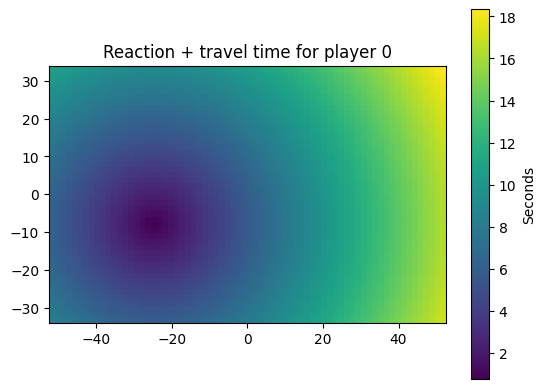

In [5]:
def arrival_surface(targets,positions,velocity,reaction=.7,run_speed=5.):
    projected=positions+reaction*velocity
    travel=np.linalg.norm(targets[:,:,None,:]-projected,axis=-1)/run_speed
    return reaction+travel
arrival=arrival_surface(targets,positions,velocity)
plt.imshow(arrival[:,:,0],origin='lower',extent=(-52.5,52.5,-34,34));plt.colorbar(label='Seconds');plt.title('Reaction + travel time for player 0');plt.show()

## 6. Compare earliest team arrivals

Take the minimum within each team, then inspect both surfaces.

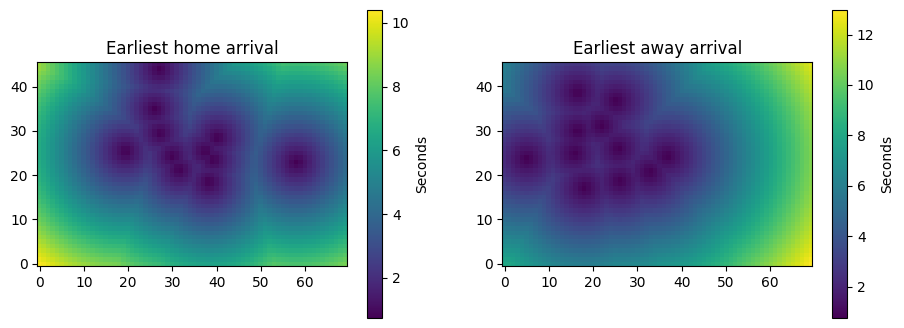

In [6]:
home_time=arrival[:,:,home].min(axis=-1);away_time=arrival[:,:,~home].min(axis=-1)
fig,axs=plt.subplots(1,2,figsize=(11,4))
for ax,data,title in zip(axs,[home_time,away_time],['Earliest home arrival','Earliest away arrival']):im=ax.imshow(data,origin='lower');ax.set_title(title);fig.colorbar(im,ax=ax,label='Seconds')
plt.show()

## 7. Prepare a bounded reachability score

This arrival-time score is the input to the area integration; it is not the final space metric.

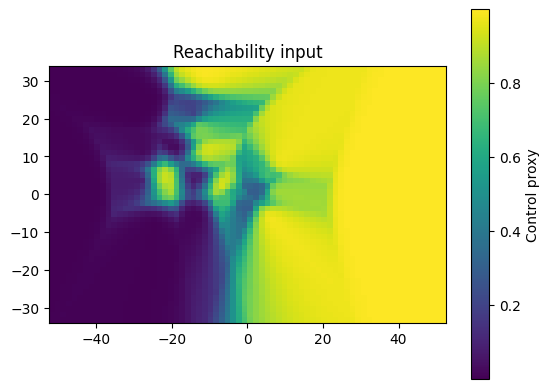

In [7]:
def sigmoid(z):
    return 1/(1+np.exp(-np.clip(z,-40,40)))
control=sigmoid((away_time-home_time)/.45)
plt.imshow(control,origin='lower',extent=(-52.5,52.5,-34,34));plt.colorbar(label='Control proxy');plt.title('Reachability input');plt.show()

## 8. Calculate cell area and per-cell accessible contributions

Expose the integration units before summing the grid.

dx, dy, cell area: 1.5217391304347814 1.5111111111111128 2.2995169082125613


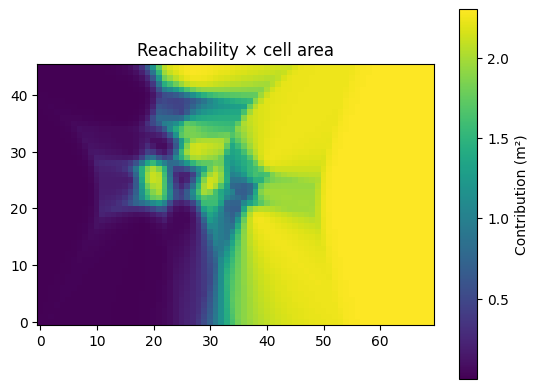

In [8]:
def integrate_surface(surface,cell_area):
    contributions=surface*cell_area
    return contributions,float(contributions.sum())
dx=X[0,1]-X[0,0];dy=Y[1,0]-Y[0,0];cell_area=dx*dy
accessible_cells,accessible_total=integrate_surface(control,cell_area)
print('dx, dy, cell area:',dx,dy,cell_area)
plt.imshow(accessible_cells,origin='lower');plt.colorbar(label='Contribution (m²)');plt.title('Reachability × cell area');plt.show()

## 9. Construct a danger weight

The chosen goal-distance weight is a separate assumption, visible before it is applied.

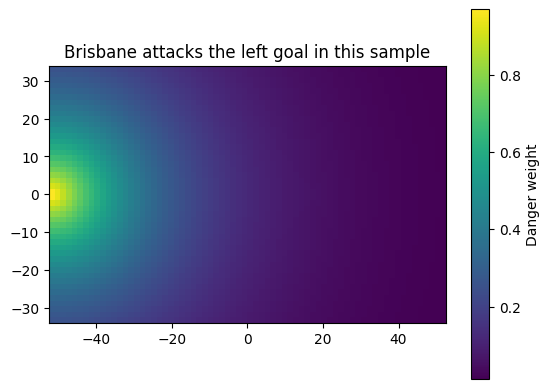

In [9]:
danger=np.exp(-np.hypot(X+52.5,Y)/25)
plt.imshow(danger,origin='lower',extent=(-52.5,52.5,-34,34));plt.colorbar(label='Danger weight');plt.title('Brisbane attacks the left goal in this sample');plt.show()

## 10. Inspect weighted cell contributions

Multiply reachability, cell area and danger at each target before producing a total.

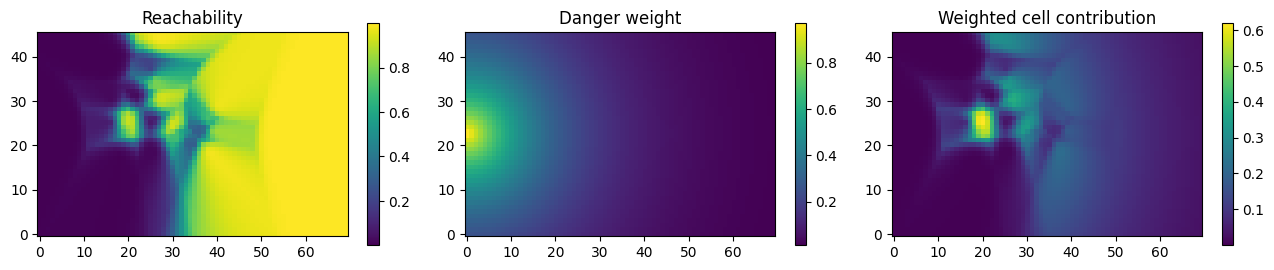

In [10]:
def space_contributions(control,danger,cell_area):
    accessible_cells=control*cell_area
    dangerous_cells=accessible_cells*danger
    return accessible_cells,dangerous_cells
accessible_cells,dangerous_cells=space_contributions(control,danger,cell_area)
fig,axs=plt.subplots(1,3,figsize=(13,4))
for ax,data,title in zip(axs,[control,danger,dangerous_cells],['Reachability','Danger weight','Weighted cell contribution']):im=ax.imshow(data,origin='lower');ax.set_title(title);fig.colorbar(im,ax=ax,shrink=.6)
plt.tight_layout();plt.show()

## 11. Final output: integrated proxy quantities

Sum the already-inspected contributions. Keep units and model boundaries attached to the numbers.

In [11]:
accessible_proxy=float(accessible_cells.sum());dangerous_proxy=float(dangerous_cells.sum())
display(pd.DataFrame({'quantity':['Accessible proxy','Danger-weighted proxy'],'total':[accessible_proxy,dangerous_proxy],'units':['m²','weighted m²']}))
assert np.isclose(accessible_total,accessible_proxy)

,quantity,total,units
0,Accessible proxy,4242.777787,m²
1,Danger-weighted proxy,276.612253,weighted m²


## Interpretation and limitations

These transparent area-integral proxies are not exact published AS/DAS. Grid resolution, reachability assumptions and chosen danger weight affect the result. The presenter notebook separately calls the actual accessible-space package.